In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import os
from pathlib import Path

import polars as pl

pl.Config(set_tbl_cols=1000)

In [3]:
data_dir = Path(os.path.abspath("")).resolve().parents[1] / "data"
data_files = tuple(data_dir.glob("*.csv"))
data_files

(PosixPath('/home/runar/github/TDT4225-ex3/data/credits.csv'),
 PosixPath('/home/runar/github/TDT4225-ex3/data/keywords.csv'),
 PosixPath('/home/runar/github/TDT4225-ex3/data/links.csv'),
 PosixPath('/home/runar/github/TDT4225-ex3/data/links_small.csv'),
 PosixPath('/home/runar/github/TDT4225-ex3/data/movies_metadata.csv'),
 PosixPath('/home/runar/github/TDT4225-ex3/data/ratings.csv'),
 PosixPath('/home/runar/github/TDT4225-ex3/data/ratings_small.csv'))

In [4]:
from polars.exceptions import ComputeError

for file in data_files:
    try:
        pl.read_csv(file)
    except ComputeError:
        print(f"{file} had problems parsing")

/home/runar/github/TDT4225-ex3/data/movies_metadata.csv had problems parsing


There's a problem in movies_metadata.csv. Some newlines have not been escaped. Fix implemented in `read_csv_merging_split_rows`:

In [5]:
from tdt4225_ex3.data_cleaning import read_csv_merging_split_rows

try:
    read_csv_merging_split_rows(data_dir / "movies_metadata.csv")
    print("Loading fixed")
except ComputeError:
    print("Loading is still failing")

Loading fixed


In [6]:
from tdt4225_ex3.data_cleaning import get_data

datasets = get_data()

Duplication checks and fixes:

In [7]:
for name, df in datasets.items():
    print(f"{name}: {df.height} rows, {df.height - df.unique().height} identical rows")

credits: 45476 rows, 37 identical rows
keywords: 46419 rows, 987 identical rows
links_small: 9125 rows, 0 identical rows
links: 45843 rows, 0 identical rows
movies_metadata: 45463 rows, 17 identical rows
ratings_small: 100004 rows, 0 identical rows
ratings: 26024289 rows, 0 identical rows


In [8]:
for name, df in datasets.items():
    if "id" not in df.columns:
        continue
    df = df.unique()
    print(f"{name}: {df.height - df['id'].n_unique()} duplicate ids")

credits: 7 duplicate ids
keywords: 0 duplicate ids
movies_metadata: 13 duplicate ids


In [9]:
def see_diff_cols_per_id(df: pl.DataFrame) -> pl.DataFrame:
    dups = df.filter(pl.col("id").is_duplicated())
    n = dups.group_by("id").agg(pl.all().n_unique()).drop("id").max()
    cols = [c for c in n.columns if n[c][0] > 1]
    return dups.select("id", *cols).sort("id")


print(see_diff_cols_per_id(datasets["movies_metadata"]))
print(see_diff_cols_per_id(datasets["credits"]))

shape: (59, 3)
┌────────┬────────────┬────────────┐
│ id     ┆ popularity ┆ vote_count │
│ ---    ┆ ---        ┆ ---        │
│ i64    ┆ f64        ┆ i64        │
╞════════╪════════════╪════════════╡
│ 4912   ┆ 11.331072  ┆ 281        │
│ 4912   ┆ 7.645827   ┆ 281        │
│ 5511   ┆ 9.091288   ┆ 187        │
│ 5511   ┆ 9.091288   ┆ 187        │
│ 10991  ┆ 10.264597  ┆ 143        │
│ …      ┆ …          ┆ …          │
│ 168538 ┆ 1.276602   ┆ 3          │
│ 265189 ┆ 12.165685  ┆ 255        │
│ 265189 ┆ 12.165685  ┆ 255        │
│ 298721 ┆ 2.535419   ┆ 50         │
│ 298721 ┆ 2.535419   ┆ 50         │
└────────┴────────────┴────────────┘
shape: (87, 2)
┌────────┬─────────────────────────────────┐
│ id     ┆ crew                            │
│ ---    ┆ ---                             │
│ i64    ┆ str                             │
╞════════╪═════════════════════════════════╡
│ 3057   ┆ [{'credit_id': '52fe4380c3a368… │
│ 3057   ┆ [{'credit_id': '52fe4380c3a368… │
│ 4912   ┆ [{'credit_id': 

Ratings use movielens ids, the rest uses tmdb ids. Checking if the links between them are one-to-one:

In [10]:
links = datasets["links"].drop_nulls("tmdbId")
links.filter(pl.col("tmdbId").is_duplicated()).sort("tmdbId")

movieId,imdbId,tmdbId
i64,i64,i64
6003,290538,4912
144606,270288,4912
7587,62229,5511
27136,165303,5511
4241,266860,10991
…,…,…
130744,84387,168538
114342,3630276,265189
175813,2121382,265189


Multiple tmdb ids have more than one movielens id, so we will store `movielens_ids` as a list on each movie.

Let's check if there are columns with not logical 0-values:

In [11]:
for col in ("budget", "revenue", "runtime", "vote_count"):
    print(
        f"{col}: {(datasets['movies_metadata'][col] == 0).sum()} zeros out of {datasets['movies_metadata'].height}"
    )

budget: 36573 zeros out of 45463
revenue: 38055 zeros out of 45463
runtime: 1558 zeros out of 45463
vote_count: 2899 zeros out of 45463


It doesnt make sense for budget, revenue and runtime to be 0 (it probably means "unknown"). Also, some movies have 0 votes, which makes vote_average for that movie not logical.

Cleaning summary:

- All:
  - Completely duplicated rows are removed.
- Metadata:
  - Only popularity and vote_count differ per id, so we keep the most votes and highest popularity.
  - Use null where there is 0 for budget, revenue and runtime.
  - Use null for vote_average when vote_count is 0
- Credits:
  - We keep the one with longest crew-list.

This is taken care of in `get_cleaned_data`.

In [12]:
from tdt4225_ex3.data_cleaning import get_cleaned_data

datasets = get_cleaned_data()

By looking at the raw csv files, we see that some columns are json objects:

- credits.csv: cast, crew
- keywords.csv: keywords
- movies_metadata.csv: belongs_to_collection, genres, production_companies, production_countries, spoken_languages

We want to see if there is a consistent schema:

In [13]:
json_columns = {
    "credits": ("cast", "crew"),
    "keywords": ("keywords",),
    "movies_metadata": (
        "belongs_to_collection",
        "genres",
        "production_companies",
        "production_countries",
        "spoken_languages",
    ),
}

In [14]:
import ast
from collections import Counter

for name, cols in json_columns.items():
    for col in cols:
        layouts = Counter()
        for value in datasets[name][col].drop_nulls():
            parsed = ast.literal_eval(value)
            if isinstance(parsed, dict):
                parsed = [parsed]
            for d in parsed:
                layouts[str({k: type(v).__name__ for k, v in sorted(d.items())})] += 1

        print(f"{name}.{col}")
        for layout, count in layouts.most_common():
            print(count, layout)
        print()

credits.cast
388366 {'cast_id': 'int', 'character': 'str', 'credit_id': 'str', 'gender': 'int', 'id': 'int', 'name': 'str', 'order': 'int', 'profile_path': 'str'}
173678 {'cast_id': 'int', 'character': 'str', 'credit_id': 'str', 'gender': 'int', 'id': 'int', 'name': 'str', 'order': 'int', 'profile_path': 'NoneType'}

credits.crew
368835 {'credit_id': 'str', 'department': 'str', 'gender': 'int', 'id': 'int', 'job': 'str', 'name': 'str', 'profile_path': 'NoneType'}
95001 {'credit_id': 'str', 'department': 'str', 'gender': 'int', 'id': 'int', 'job': 'str', 'name': 'str', 'profile_path': 'str'}

keywords.keywords
156602 {'id': 'int', 'name': 'str'}

movies_metadata.belongs_to_collection
3235 {'backdrop_path': 'str', 'id': 'int', 'name': 'str', 'poster_path': 'str'}
710 {'backdrop_path': 'NoneType', 'id': 'int', 'name': 'str', 'poster_path': 'str'}
517 {'backdrop_path': 'NoneType', 'id': 'int', 'name': 'str', 'poster_path': 'NoneType'}
26 {'backdrop_path': 'str', 'id': 'int', 'name': 'str',

If we treat None as empty string (which is reasonable), we see that all the columns have a consistent schema! This will be good for queries later, as we know that if one of the columns have data, we know exactly how to retrieve it.

Before deciding on collections, we check referential integrity between the files: does every id point at something that exists?

In [15]:
movies_meta = datasets["movies_metadata"]
links = datasets["links"].drop_nulls("tmdbId")
ratings = datasets["ratings"]


def missing(name, ids: pl.Series, reference: pl.Series):
    return ids.unique().filter(~ids.unique().is_in(reference.implode()))


def n_missing(name, ids: pl.Series, reference: pl.Series):
    print(
        f"{name}: {missing(name, ids, reference).len()} of {ids.n_unique()} distinct ids are missing"
    )


n_missing("credits -> movies_metadata", datasets["credits"]["id"], movies_meta["id"])
n_missing("keywords -> movies_metadata", datasets["keywords"]["id"], movies_meta["id"])
n_missing("links (tmdbId) -> movies_metadata", links["tmdbId"], movies_meta["id"])
n_missing("ratings -> links", ratings["movieId"], datasets["links"]["movieId"])
n_missing("movies_metadata -> credits", movies_meta["id"], datasets["credits"]["id"])
n_missing("movies_metadata -> keywords", movies_meta["id"], datasets["keywords"]["id"])
n_missing("movies_metadata -> links (tmdbId)", movies_meta["id"], links["tmdbId"])

credits -> movies_metadata: 0 of 45432 distinct ids are missing
keywords -> movies_metadata: 0 of 45432 distinct ids are missing
links (tmdbId) -> movies_metadata: 161 of 45594 distinct ids are missing
ratings -> links: 0 of 45115 distinct ids are missing
movies_metadata -> credits: 1 of 45433 distinct ids are missing
movies_metadata -> keywords: 1 of 45433 distinct ids are missing
movies_metadata -> links (tmdbId): 0 of 45433 distinct ids are missing


In [16]:
missing_credits = missing(
    "movies_metadata -> credits",
    movies_meta["id"],
    datasets["credits"]["id"],
)

missing_keywords = missing(
    "movies_metadata -> keywords",
    movies_meta["id"],
    datasets["keywords"]["id"],
)

print(set(missing_credits.to_list()) == set(missing_keywords.to_list()))

True


Some links have no `tmdbId` and some point at movies that do not exist in `movies_metadata`. How many ratings does that affect?

In [17]:
print(
    f"links without tmdbId: {datasets['links']['tmdbId'].null_count()} of {datasets['links'].height}"
)

valid_movielens_ids = links.filter(pl.col("tmdbId").is_in(movies_meta["id"].implode()))[
    "movieId"
]
n_valid = ratings.filter(pl.col("movieId").is_in(valid_movielens_ids.implode())).height
print(
    f"ratings pointing at an existing movie: {n_valid} of {ratings.height}. "
    f"This gives {ratings.height - n_valid} dangling references."
)

rated_tmdb_ids = links.filter(pl.col("movieId").is_in(ratings["movieId"].implode()))[
    "tmdbId"
]
n_missing(
    "movies_metadata -> movies with at least one rating",
    movies_meta["id"],
    rated_tmdb_ids,
)

links without tmdbId: 219 of 45843
ratings pointing at an existing movie: 25981582 of 26024289. This gives 42707 dangling references.
movies_metadata -> movies with at least one rating: 722 of 45433 distinct ids are missing


Could `imdbId` recover the links that `tmdbId` cannot resolve? `movies_metadata` has an `imdb_id` column, so we match on it (zero-padded and prefixed with `tt`).

In [18]:
unlinked = (
    datasets["links"]
    .filter(~pl.col("movieId").is_in(valid_movielens_ids.implode()))
    .with_columns(
        imdb_id=pl.format("tt{}", pl.col("imdbId").cast(pl.Utf8).str.zfill(7))
    )
)
recovered = unlinked.filter(pl.col("imdb_id").is_in(movies_meta["imdb_id"].implode()))
print(f"links without a valid movie: {unlinked.height}")
print(f"of those, found in movies_metadata via imdb_id: {recovered.height}")

links without a valid movie: 380
of those, found in movies_metadata via imdb_id: 0


None are found via `imdb_id` either. These movies are not in `movies_metadata`.

Are there duplicates in the ratings, and is `ratings_small` a subset of `ratings`?

In [19]:
print(
    "duplicate (userId, movieId) pairs:",
    ratings.height - ratings.select("userId", "movieId").n_unique(),
)
print(
    "ratings_small rows not found in ratings:",
    datasets["ratings_small"].join(ratings, on=ratings.columns, how="anti").height,
)
print(
    "distinct users: ratings",
    ratings["userId"].n_unique(),
    "ratings_small",
    datasets["ratings_small"]["userId"].n_unique(),
)

duplicate (userId, movieId) pairs: 0
ratings_small rows not found in ratings: 100004
distinct users: ratings 270896 ratings_small 671


We decide to have two collections following the [rules of thumb for MongoDB schema design](https://www.mongodb.com/company/blog/mongodb/6-rules-of-thumb-for-mongodb-schema-design): movies and ratings. The movies collection hold all relevant data per movie, including crew, cast, keywords, genres, ..., even though that means some duplicate storage. This is fine because thedata here will rarely change. Ratings may update really frequently, so that will be stored in its own collection, with reference to the movies collection.

In [20]:
from tdt4225_ex3.data_cleaning import build_movies

movies = build_movies(datasets)

In [21]:
from pprint import pprint

pprint(next(m for m in movies if m["title"] == "Interstellar"))

{'_id': 157336,
 'adult': False,
 'belongs_to_collection': None,
 'budget': 165000000,
 'cast': [{'cast_id': 9,
           'character': 'Joseph Cooper',
           'credit_id': '52fe4bbf9251416c910e47cb',
           'gender': 2,
           'id': 10297,
           'name': 'Matthew McConaughey',
           'order': 0,
           'profile_path': '/uKj2m1hJSw4dlOLAvZ3g9WiZkAZ.jpg'},
          {'cast_id': 17,
           'character': 'Murph Cooper',
           'credit_id': '52fe4bbf9251416c910e47f1',
           'gender': 1,
           'id': 83002,
           'name': 'Jessica Chastain',
           'order': 1,
           'profile_path': '/eyv98YlnRuOOUNCD1U6w2yZDRA2.jpg'},
          {'cast_id': 169,
           'character': 'Dr. Amelia Brand',
           'credit_id': '57fe146fc3a368504a00261e',
           'gender': 1,
           'id': 1813,
           'name': 'Anne Hathaway',
           'order': 2,
           'profile_path': '/jUMOKwSUBnTcMeN1HfhutiY49Ad.jpg'},
          {'cast_id': 18,
       

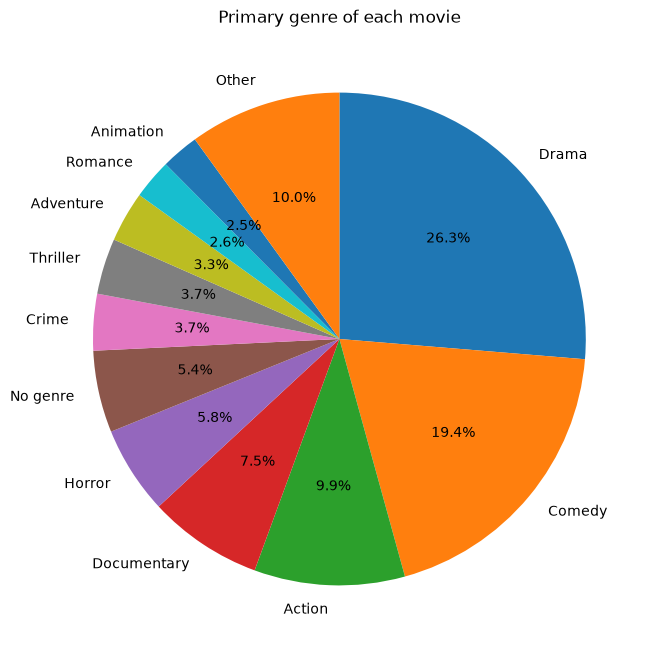

In [22]:
import matplotlib.pyplot as plt

genre_counts = (
    pl.Series(
        "genre",
        [m["genres"][0]["name"] for m in movies if m["genres"]]
        + ["No genre"] * sum(1 for m in movies if not m["genres"]),
    )
    .value_counts(sort=True)
    .with_columns(share=pl.col("count") / pl.col("count").sum())
)
big = genre_counts.filter(pl.col("share") >= 0.02)
other = genre_counts.filter(pl.col("share") < 0.02)["count"].sum()

fig, ax = plt.subplots(figsize=(8, 8))
ax.pie(
    [*big["count"], other],
    labels=[*big["genre"], "Other"],
    autopct="%1.1f%%",
    startangle=90,
    counterclock=False,
)
ax.set_title("Primary genre of each movie")
plt.show()

Genre distribution using all genres. A movie can have several genres, so it counts towards each of them and each slice shows the share of genre occurrences (the slices sum to 100%, but the number of movies is lower than the number of occurrences). Genres under 2% are grouped as "Other":

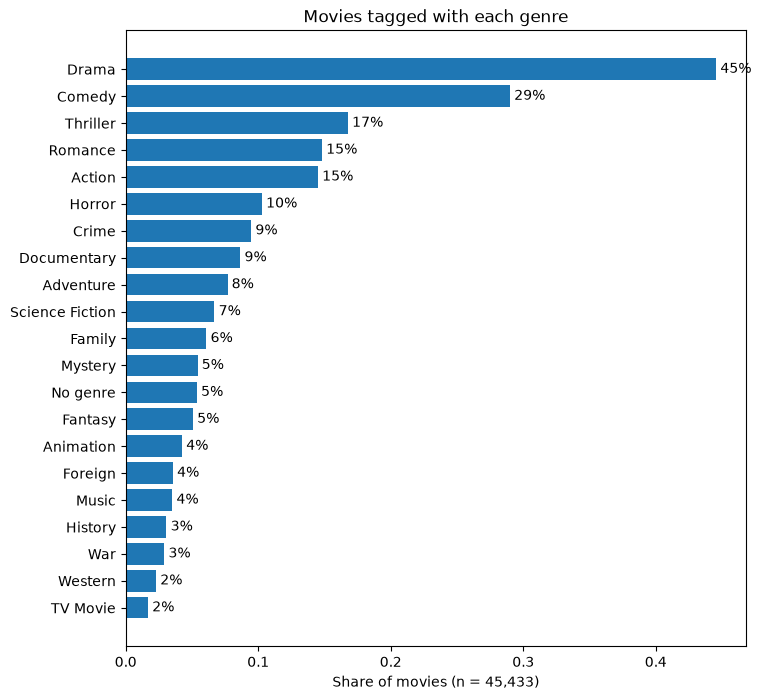

In [23]:
import matplotlib.pyplot as plt

n_movies = len(movies)
genre_counts = (
    pl.Series(
        "genre",
        [g["name"] for m in movies for g in m["genres"]]
        + ["No genre"] * sum(1 for m in movies if not m["genres"]),
    )
    .value_counts(sort=True)
    .with_columns(share=pl.col("count") / n_movies)
)

fig, ax = plt.subplots(figsize=(8, 8))
bars = ax.barh(genre_counts["genre"], genre_counts["share"])
ax.invert_yaxis()
ax.bar_label(bars, labels=[f"{s:.0%}" for s in genre_counts["share"]], padding=3)
ax.set_xlabel(f"Share of movies (n = {n_movies:,})")
ax.set_title("Movies tagged with each genre")
plt.show()